# Практическая работа № 7. Случайный лес

**Уровень:** C  
**Студент:** Кашымбеков Актан Ийгиликович

## Цель работы

Обучить случайный лес для предсказания цены подержанного автомобиля,
сравнить его с одиночным деревом решений и исследовать модель
с помощью встроенной важности признаков, permutation importance и SHAP.

## Данные и задача

Используется used_cars.csv из предыдущих практических работ.
Одна строка соответствует объявлению о продаже автомобиля.

Целевая переменная — цена price в долларах США.
Задача машинного обучения — регрессия.

ПР-6 выполняется отдельно и не используется в этой работе.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

c:\Users\lulu\Documents\Projects\ml_course\ml-social-media-sleep\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1
SHAP: 0.53.0


In [4]:
project_dirs = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "ml-social-media-sleep"]

DATA_PATH = next(
    (
        folder / "data" / "raw" / "used_cars.csv"
        for folder in project_dirs
        if (folder / "data" / "raw" / "used_cars.csv").is_file()
    ),
    None,
)

if DATA_PATH is None:
    raise FileNotFoundError("Не найден data/raw/used_cars.csv. Проверь папку проекта.")

df = pd.read_csv(DATA_PATH)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## Используемые признаки

Для сопоставимости с задачей ПР-4 используются те же шесть исходных признаков:

- brand — марка;
- model_year — модельный год;
- milage — пробег в милях;
- fuel_type — вид топлива;
- accident — сведения об авариях;
- clean_title — отметка clean title в объявлении.

Цена price является целевой переменной и не входит в признаки.

In [5]:
FEATURES = [
    "brand",
    "model_year",
    "milage",
    "fuel_type",
    "accident",
    "clean_title",
]

numeric_features = ["model_year", "milage"]

categorical_features = [
    "brand",
    "fuel_type",
    "accident",
    "clean_title",
]

X = df[FEATURES].copy()

price_text = (
    df["price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

y = pd.to_numeric(price_text, errors="coerce").astype(float)

milage_text = (
    X["milage"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("mi.", "", regex=False)
    .str.strip()
)

X["milage"] = pd.to_numeric(
    milage_text,
    errors="coerce",
).astype(float)

X["model_year"] = pd.to_numeric(
    X["model_year"],
    errors="coerce",
).astype(float)

for column in numeric_features:
    X[column] = X[column].where(
        np.isfinite(X[column]),
        np.nan,
    )

X["milage"] = X["milage"].where(X["milage"] >= 0, np.nan)

for column in categorical_features:
    values = X[column].astype("string").str.strip()

    values = values.replace({
        "": pd.NA,
        "\ufffd": pd.NA,
        "not supported": pd.NA,
    })

    X[column] = (
        values.astype(object)
        .where(values.notna(), np.nan)
    )

assert np.isfinite(y.to_numpy()).all(), "Есть некорректные цены"
assert (y > 0).all(), "Есть неположительные цены"
assert "price" not in X.columns

print("Пропуски в признаках:")
display(X.isna().sum())

display(pd.DataFrame({
    "Цена исходная": df["price"].head(),
    "Цена, USD": y.head(),
    "Пробег исходный": df["milage"].head(),
    "Пробег, мили": X["milage"].head(),
}))

Пропуски в признаках:


brand            0
model_year       0
milage           0
fuel_type      172
accident       113
clean_title    596
dtype: int64

,Цена исходная,"Цена, USD",Пробег исходный,"Пробег, мили"
0,"$10,300",10300.0,"51,000 mi.",51000.0
1,"$38,005",38005.0,"34,742 mi.",34742.0
2,"$54,598",54598.0,"22,372 mi.",22372.0
3,"$15,500",15500.0,"88,900 mi.",88900.0
4,"$34,999",34999.0,"9,835 mi.",9835.0


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

Train: (3207, 6)
Test: (802, 6)


## Схема оценки

Данные разделены на train и test в отношении 80/20
с random_state=42.

Дерево решений и случайный лес обучаются на одном train
и оцениваются на одном test.

Параметры леса выбираются только внутри train с помощью
трёхкратной кросс-валидации. Test используется после выбора модели.

Основная метрика — MAE. Дополнительно рассчитываются RMSE и R².

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="__UNKNOWN__",
        ),
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

## Предобработка

Пропуски числовых признаков заполняются медианами обучающей части.
Пропуски категориальных признаков заменяются отдельной категорией.
Категории преобразуются с помощью OneHotEncoder.

Предобработка включена в Pipeline: при кросс-валидации она заново
обучается только на обучающей части каждого разбиения.

По сравнению с ПР-4 предобработка упрощена: масштабирование
и дополнительный relative_milage не используются.
Для деревьев масштабирование не требуется; в этой работе
интерпретируются шесть исходных характеристик автомобиля.

In [8]:
forest_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    ),
])

param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [1, 5],
}

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=False,
    verbose=1,
)

search.fit(X_train, y_train)

forest = search.best_estimator_

print("Лучшие параметры:")
print(search.best_params_)

print("Средняя CV MAE, USD:", -search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Лучшие параметры:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Средняя CV MAE, USD: 14222.801440685309


In [9]:
cv_results = pd.DataFrame(search.cv_results_)

cv_table = pd.DataFrame({
    "Количество деревьев": cv_results["param_model__n_estimators"],
    "Максимальная глубина": cv_results["param_model__max_depth"],
    "Минимум объектов в листе": cv_results["param_model__min_samples_leaf"],
    "CV MAE, USD": -cv_results["mean_test_score"],
    "CV MAE std, USD": cv_results["std_test_score"],
})

cv_table = cv_table.sort_values("CV MAE, USD")

display(cv_table.round(2))

,Количество деревьев,Максимальная глубина,Минимум объектов в листе,"CV MAE, USD","CV MAE std, USD"
5,300,None,1,14222.80,1084.68
4,100,None,1,14269.61,1079.28
0,100,10,1,14709.84,948.17
1,300,10,1,14720.64,956.18
3,300,10,5,16615.74,787.24
7,300,None,5,16640.34,771.18
2,100,10,5,16643.89,744.94
6,100,None,5,16671.98,741.38


## Выбор параметров случайного леса

Проверены восемь комбинаций параметров с помощью
трёхкратной кросс-валидации только на обучающей выборке.

Наименьшая средняя MAE получена при следующих параметрах:

- n_estimators = 300;
- max_depth = None;
- min_samples_leaf = 1.

Средняя CV MAE составила 14 222,80 USD.

Количество 300 деревьев выбрано по результатам сравнения
с вариантом из 100 деревьев в исследованной сетке параметров.
Этот результат не доказывает, что 300 — оптимальное количество
среди всех возможных значений.

Тестовая выборка при подборе параметров не использовалась.

In [10]:
tree = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        DecisionTreeRegressor(
            max_depth=search.best_params_["model__max_depth"],
            min_samples_leaf=search.best_params_["model__min_samples_leaf"],
            random_state=RANDOM_STATE,
        ),
    ),
])

tree.fit(X_train, y_train)

print("Дерево обучено.")
print("Глубина дерева:", tree.named_steps["model"].get_depth())
print("Количество листьев:", tree.named_steps["model"].get_n_leaves())

Дерево обучено.
Глубина дерева: 48
Количество листьев: 3153


In [11]:
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)


def calculate_metrics(model, X_part, y_part):
    prediction = model.predict(X_part)

    return {
        "MAE, USD": mean_absolute_error(y_part, prediction),
        "RMSE, USD": np.sqrt(
            mean_squared_error(y_part, prediction)
        ),
        "R²": r2_score(y_part, prediction),
    }


models = {
    "Медианный baseline": baseline,
    "Одиночное дерево": tree,
    "Случайный лес": forest,
}

rows = []

for model_name, model in models.items():
    for sample_name, X_part, y_part in [
        ("train", X_train, y_train),
        ("test", X_test, y_test),
    ]:
        metrics = calculate_metrics(model, X_part, y_part)

        rows.append({
            "Модель": model_name,
            "Выборка": sample_name,
            **metrics,
        })

metrics_table = pd.DataFrame(rows)

display(metrics_table.round(3))

,Модель,Выборка,"MAE, USD","RMSE, USD",R²
0,Медианный baseline,train,25584.506,52544.585,-0.053
1,Медианный baseline,test,32865.970,144218.917,-0.018
2,Одиночное дерево,train,37.047,931.504,1.000
3,Одиночное дерево,test,25270.645,135584.793,0.101
4,Случайный лес,train,5211.233,10773.498,0.956
5,Случайный лес,test,21808.884,135476.468,0.102


In [12]:
test_comparison = (
    metrics_table[
        (metrics_table["Выборка"] == "test")
        & metrics_table["Модель"].isin([
            "Одиночное дерево",
            "Случайный лес",
        ])
    ]
    .set_index("Модель")
    [["MAE, USD", "RMSE, USD", "R²"]]
)

display(test_comparison.round(3))

mae_tree = test_comparison.loc["Одиночное дерево", "MAE, USD"]
mae_forest = test_comparison.loc["Случайный лес", "MAE, USD"]

print(
    "MAE дерева − MAE леса:",
    round(mae_tree - mae_forest, 2),
    "USD",
)

,"MAE, USD","RMSE, USD",R²
Модель,,,
Одиночное дерево,25270.645,135584.793,0.101
Случайный лес,21808.884,135476.468,0.102


MAE дерева − MAE леса: 3461.76 USD


## Сравнение дерева и случайного леса

Обе модели обучены на одной обучающей выборке и оценены
на одной тестовой выборке с одинаковыми исходными признаками.

Test MAE одиночного дерева составила 25 270,65 USD,
случайного леса — 21 808,88 USD.
Лес уменьшил среднюю абсолютную ошибку на 3 461,76 USD,
или примерно на 13,7%.

При этом RMSE изменилась незначительно:
135 584,79 USD у дерева против 135 476,47 USD у леса.
Следовательно, улучшение по MAE не сопровождалось
существенным уменьшением ошибки по RMSE.

У одиночного дерева наблюдается большой разрыв между
train MAE (37,05 USD) и test MAE (25 270,65 USD),
что указывает на переобучение. У леса этот разрыв меньше,
но сохраняется.

Случайный лес лучше по основной метрике MAE на данном test,
однако R² около 0,10 свидетельствует об ограниченном
качестве предсказаний.

In [13]:
fitted_preprocessor = forest.named_steps["preprocessor"]
forest_model = forest.named_steps["model"]

encoded_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

onehot = (
    fitted_preprocessor
    .named_transformers_["categorical"]
    .named_steps["onehot"]
)

feature_groups = list(numeric_features)

for column, categories in zip(
    categorical_features,
    onehot.categories_,
):
    feature_groups.extend([column] * len(categories))

assert (
    len(feature_groups)
    == len(encoded_feature_names)
    == len(forest_model.feature_importances_)
)

mdi_encoded = pd.DataFrame({
    "Столбец после обработки": encoded_feature_names,
    "Признак": feature_groups,
    "MDI": forest_model.feature_importances_,
})

mdi = (
    mdi_encoded
    .groupby("Признак")["MDI"]
    .sum()
    .reindex(FEATURES)
    .sort_values(ascending=False)
)

display(mdi.rename("Встроенная важность").to_frame())

print("Сумма важностей:", mdi.sum())
print("Два первых признака:", mdi.index[:2].tolist())

,Встроенная важность
Признак,
brand,0.455248
milage,0.431639
model_year,0.079958
clean_title,0.013480
fuel_type,0.011703
accident,0.007972


Сумма важностей: 1.0
Два первых признака: ['brand', 'milage']


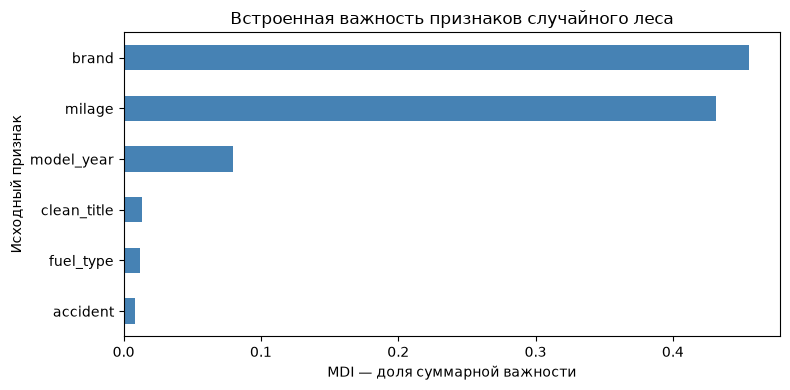

In [14]:
mdi.sort_values().plot.barh(
    figsize=(8, 4),
    color="steelblue",
)

plt.title("Встроенная важность признаков случайного леса")
plt.xlabel("MDI — доля суммарной важности")
plt.ylabel("Исходный признак")
plt.tight_layout()
plt.show()

In [15]:
permutation = permutation_importance(
    estimator=forest,
    X=X_test,
    y=y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

pi_table = pd.DataFrame({
    "Permutation ΔMAE, USD": permutation.importances_mean,
    "Разброс, USD": permutation.importances_std,
}, index=X_test.columns)

pi_table.index.name = "Признак"

pi_table = pi_table.sort_values(
    "Permutation ΔMAE, USD",
    ascending=False,
)

display(pi_table.round(2))

,"Permutation ΔMAE, USD","Разброс, USD"
Признак,,
milage,12353.39,901.08
brand,7760.00,516.28
model_year,4827.46,123.93
fuel_type,451.57,61.84
clean_title,7.03,32.61
accident,-34.58,47.41


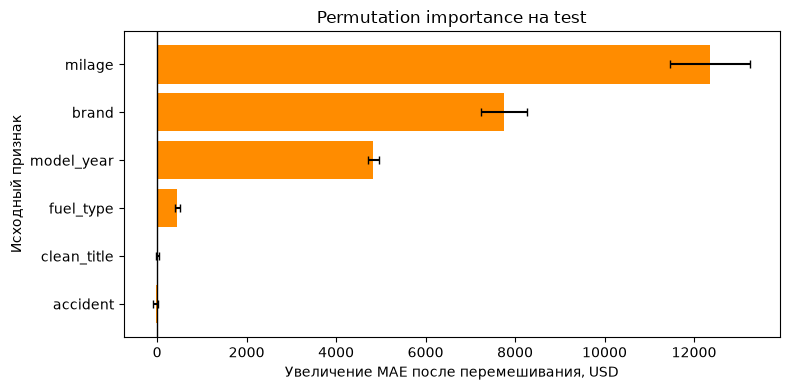

In [16]:
pi_plot = pi_table.sort_values("Permutation ΔMAE, USD")

plt.figure(figsize=(8, 4))

plt.barh(
    pi_plot.index,
    pi_plot["Permutation ΔMAE, USD"],
    xerr=pi_plot["Разброс, USD"],
    color="darkorange",
    capsize=3,
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation importance на test")
plt.xlabel("Увеличение MAE после перемешивания, USD")
plt.ylabel("Исходный признак")
plt.tight_layout()
plt.show()

In [17]:
importance_comparison = pd.DataFrame({
    "MDI": mdi.reindex(FEATURES),
    "Permutation ΔMAE, USD": (
        pi_table["Permutation ΔMAE, USD"].reindex(FEATURES)
    ),
    "Permutation std, USD": (
        pi_table["Разброс, USD"].reindex(FEATURES)
    ),
})

importance_comparison["Место MDI"] = (
    importance_comparison["MDI"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison["Место permutation"] = (
    importance_comparison["Permutation ΔMAE, USD"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(
    importance_comparison
    .sort_values("Место MDI")
    .round(3)
)

,MDI,"Permutation ΔMAE, USD","Permutation std, USD",Место MDI,Место permutation
Признак,,,,,
brand,0.455,7760.000,516.275,1,2
milage,0.432,12353.394,901.082,2,1
model_year,0.080,4827.456,123.933,3,3
clean_title,0.013,7.033,32.614,4,5
fuel_type,0.012,451.572,61.837,5,4
accident,0.008,-34.575,47.412,6,6


## Сравнение встроенной важности и permutation importance

Оба метода выделили марку, пробег и модельный год как три
наиболее важных признака, однако их порядок различается.

Встроенная важность поставила марку на первое место:
MDI brand = 0,455, milage = 0,432.
Permutation importance поставила на первое место пробег:
его перемешивание увеличило test MAE в среднем на
12 353,39 USD, а перемешивание марки — на 7 760,00 USD.

Методы измеряют разные характеристики. MDI отражает уменьшение
неоднородности цены при построении деревьев на train.
Permutation importance показывает, насколько ухудшается
выбранная метрика уже обученной модели при перемешивании
признака на test. Кроме того, деревья обучались с критерием
квадратичной ошибки, а permutation importance оценивалась по MAE.

Встроенная важность может завышать значимость признаков
с большим количеством уникальных значений. Это ограничение
актуально, например, для числового пробега. Для категориальных
признаков здесь суммировались важности всех one-hot столбцов.

Коррелирующие признаки могут частично заменять друг друга:
после перемешивания одного модель продолжает получать похожую
информацию из другого. Это возможная причина расхождений,
но влияние корреляций в этой работе отдельно не установлено.

Для clean_title изменение MAE составило 7,03 USD
при разбросе 32,61 USD, для accident — −34,58 USD
при разбросе 47,41 USD. Эти результаты не дают убедительного
основания объявлять признаки бесполезными или удалять их
без отдельного эксперимента.

Важности описывают поведение модели и не доказывают
причинно-следственные связи.

In [18]:
price_order = np.argsort(y_test.to_numpy())

selected_positions = price_order[
    [
        int((len(price_order) - 1) * 0.10),
        int((len(price_order) - 1) * 0.50),
        int((len(price_order) - 1) * 0.90),
    ]
]

X_examples = X_test.iloc[selected_positions].copy()
y_examples = y_test.iloc[selected_positions].copy()

example_predictions = forest.predict(X_examples)

examples_table = X_examples.copy()
examples_table["Фактическая цена, USD"] = y_examples
examples_table["Прогноз, USD"] = example_predictions
examples_table["Абсолютная ошибка, USD"] = np.abs(
    y_examples.to_numpy() - example_predictions
)

display(examples_table.round(2))

Признак,brand,model_year,milage,fuel_type,accident,clean_title,"Фактическая цена, USD","Прогноз, USD","Абсолютная ошибка, USD"
3984,Toyota,1994.0,178416.0,–,None reported,Yes,9000.0,16089.10,7089.10
56,Nissan,2023.0,1094.0,Gasoline,None reported,NaN,30999.0,54060.43,23061.43
1163,BMW,2020.0,23430.0,Gasoline,None reported,NaN,80998.0,41433.24,39564.76


In [19]:
X_examples_ready = fitted_preprocessor.transform(X_examples)

explainer = shap.TreeExplainer(
    forest_model,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
    feature_names=encoded_feature_names.tolist(),
)

shap_values = explainer(X_examples_ready)

print("Размер SHAP:", shap_values.values.shape)

shap_reconstructed = (
    np.asarray(shap_values.base_values).reshape(-1)
    + shap_values.values.sum(axis=1)
)

np.testing.assert_allclose(
    shap_reconstructed,
    example_predictions,
    rtol=1e-5,
    atol=1e-3,
)

print("Проверка пройдена: SHAP-вклады складываются в прогноз.")

Размер SHAP: (3, 70)
Проверка пройдена: SHAP-вклады складываются в прогноз.


In [20]:
group_array = np.asarray(feature_groups)

grouped_shap_values = np.column_stack([
    shap_values.values[:, group_array == feature].sum(axis=1)
    for feature in FEATURES
])

grouped_shap = shap.Explanation(
    values=grouped_shap_values,
    base_values=np.asarray(
        shap_values.base_values
    ).reshape(-1),
    feature_names=FEATURES,
)


np.testing.assert_allclose(
    grouped_shap_values.sum(axis=1),
    shap_values.values.sum(axis=1),
    rtol=1e-5,
    atol=1e-3,
)

shap_contributions = pd.DataFrame(
    grouped_shap_values,
    index=X_examples.index,
    columns=FEATURES,
)

print("SHAP-вклады в USD:")
display(shap_contributions.round(2))

SHAP-вклады в USD:


,brand,model_year,milage,fuel_type,accident,clean_title
3984,-3486.58,-5757.58,-18325.39,-81.68,514.16,79.13
56,-39584.82,3992.38,49477.42,-649.60,-742.15,-1579.82
1163,-8628.47,4998.91,3744.71,-605.07,-307.19,-916.67



Автомобиль с индексом 3984


Признак,brand,model_year,milage,fuel_type,accident,clean_title
3984,Toyota,1994.0,178416.0,–,None reported,Yes


Фактическая цена: 9000.0 USD
Прогноз: 16089.1 USD
Базовое значение: 43147.03 USD


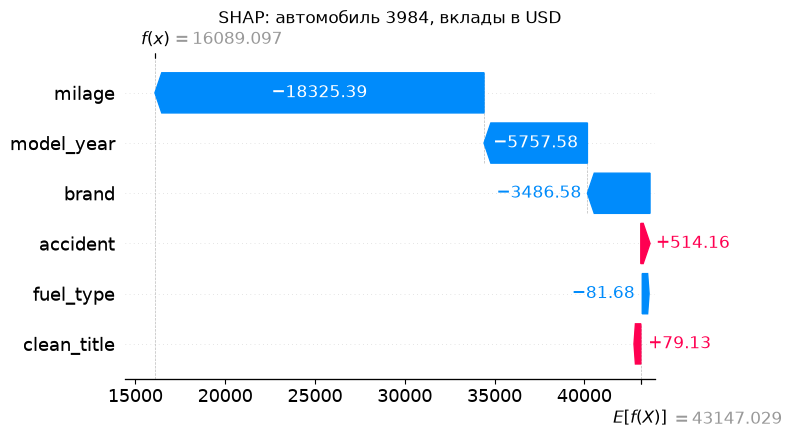


Автомобиль с индексом 56


Признак,brand,model_year,milage,fuel_type,accident,clean_title
56,Nissan,2023.0,1094.0,Gasoline,None reported,NaN


Фактическая цена: 30999.0 USD
Прогноз: 54060.43 USD
Базовое значение: 43147.03 USD


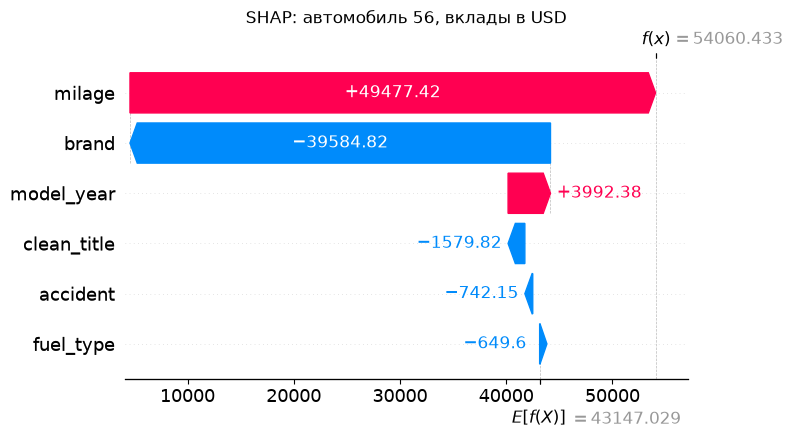


Автомобиль с индексом 1163


Признак,brand,model_year,milage,fuel_type,accident,clean_title
1163,BMW,2020.0,23430.0,Gasoline,None reported,NaN


Фактическая цена: 80998.0 USD
Прогноз: 41433.24 USD
Базовое значение: 43147.03 USD


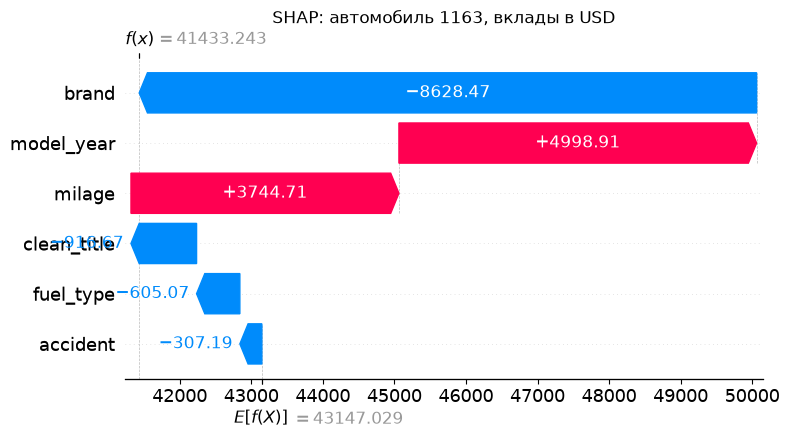

In [21]:
for i, row_index in enumerate(X_examples.index):
    print(f"\nАвтомобиль с индексом {row_index}")

    display(X_examples.iloc[[i]])

    print(
        "Фактическая цена:",
        round(float(y_examples.iloc[i]), 2),
        "USD",
    )
    print(
        "Прогноз:",
        round(float(example_predictions[i]), 2),
        "USD",
    )
    print(
        "Базовое значение:",
        round(float(grouped_shap.base_values[i]), 2),
        "USD",
    )

    shap.plots.waterfall(
        grouped_shap[i],
        max_display=len(FEATURES),
        show=False,
    )

    plt.title(f"SHAP: автомобиль {row_index}, вклады в USD")
    plt.tight_layout()
    plt.show()

## Объяснение отдельных предсказаний с помощью SHAP

SHAP рассчитан для трёх автомобилей из test.
Базовое значение модели составило 43 147,03 USD.
Прибавление SHAP-вкладов к базовому значению воспроизводит
прогноз леса; это проверено программно.

Вклады one-hot столбцов суммированы по исходным признакам.
Все приведённые вклады измеряются в USD.

### Автомобиль 3984: Toyota, 1994 год, пробег 178 416 миль

Фактическая цена — 9 000 USD.
Прогноз модели — 16 089,10 USD.
Модель завысила цену на 7 089,10 USD.

Наиболее сильный отрицательный вклад дал пробег:
−18 325,39 USD. Модельный год также снизил прогноз
на 5 757,58 USD, а группа признаков марки — на 3 486,58 USD.

Вклады остальных признаков были значительно меньше.
Таким образом, прогноз оказался ниже базового значения
прежде всего за счёт пробега и модельного года,
но всё равно превысил фактическую цену.

Значение «–» в fuel_type не является названием топлива:
в текущей предобработке оно сохранилось отдельной категорией.

### Автомобиль 56: Nissan, 2023 год, пробег 1 094 мили

Фактическая цена — 30 999 USD.
Прогноз модели — 54 060,43 USD.
Модель завысила цену на 23 061,43 USD.

Пробег дал большой положительный вклад: +49 477,42 USD.
Модельный год также повысил прогноз на 3 992,38 USD.
Эти вклады частично компенсировались отрицательным вкладом
группы признаков марки: −39 584,82 USD.

В результате прогноз оказался выше базового значения.
Этот пример показывает, что крупные положительные
и отрицательные вклады могут компенсировать друг друга.

### Автомобиль 1163: BMW, 2020 год, пробег 23 430 миль

Фактическая цена — 80 998 USD.
Прогноз модели — 41 433,24 USD.
Модель занизила цену на 39 564,76 USD.

Модельный год повысил прогноз на 4 998,91 USD,
а пробег — на 3 744,71 USD.
Однако группа признаков марки дала отрицательный вклад
−8 628,47 USD. Остальные вклады также были отрицательными,
но меньше по модулю.

Прогноз оказался немного ниже базового значения
и существенно ниже фактической цены.

### Что показывает SHAP

MDI и permutation importance характеризуют важность признаков
для модели в целом. SHAP показывает направление и величину
вкладов признаков для отдельного объекта.

Один и тот же признак может повышать прогноз для одного
автомобиля и понижать его для другого. Например, вклад пробега
отрицателен для Toyota, но положителен для Nissan и BMW.

SHAP объясняет полученное предсказание, а не фактическую цену
и не причину ошибки модели. Даже при большой ошибке прогноза
SHAP-вклады корректно складываются в этот прогноз.

Полученные объяснения не доказывают причинно-следственных связей.

## Итоговый вывод

В работе обучен RandomForestRegressor для предсказания цены
подержанного автомобиля. Использованы шесть исходных признаков.
Предобработка включена в Pipeline и обучалась только
на обучающих данных.

Параметры леса выбраны по MAE с помощью трёхкратной
кросс-валидации на train. Среди восьми комбинаций выбраны
300 деревьев, max_depth=None и min_samples_leaf=1.
Средняя CV MAE составила 14 222,80 USD.

Вариант из 100 деревьев с такими же остальными параметрами
получил CV MAE 14 269,61 USD. Поэтому преимущество 300 деревьев
в исследованной сетке небольшое; статистическая значимость
этой разницы не установлена.

Одиночное дерево и случайный лес сравнивались на одинаковых
train/test и с одинаковыми исходными признаками.
Test MAE леса составила 21 808,88 USD против 25 270,65 USD
у дерева: улучшение около 13,7%.
При этом разница RMSE мала, а test R² леса составляет
около 0,10, поэтому качество модели остаётся ограниченным.

Встроенная важность поставила на первое место марку,
а permutation importance — пробег. Оба метода включили
марку, пробег и модельный год в тройку наиболее важных признаков.

Расхождения объясняются различиями методов:
MDI оценивает уменьшение неоднородности при обучении,
а permutation importance — изменение test MAE при перемешивании.
MDI может завышать важность признаков с большим количеством
уникальных значений. Коррелирующие признаки также могут
влиять на распределение важностей, однако их влияние
в этой работе отдельно не проверялось.

SHAP применён к трём отдельным test-объектам.
Он показал величину и направление вкладов признаков
в конкретные предсказания — информацию, которой не дают
первые два метода в использованном виде.
Проверка аддитивности SHAP пройдена.

Важность признаков и SHAP-вклады описывают поведение модели,
а не причинное влияние характеристик на цену автомобиля.